I am using a dataset containing different variables related to students lives and academic performance. I am exploring the relationships between these variables and final grades to identify which factors appear to be associated with students academic performance.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns


In [4]:
df = pd.read_csv('student-mat.csv', sep=";")

The dataset was mostly clean. I checked the dataset structure, column information and missing values and found no missing values that needed to be removed.

In [5]:
df.shape

(395, 33)

In [6]:
df.head(10)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,12,12,11
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,6,6,5,6
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,16,18,19
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,14,15,15


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [8]:
pd.isnull(df).sum()


school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [9]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Text(0, 0.5, 'Number of Students')

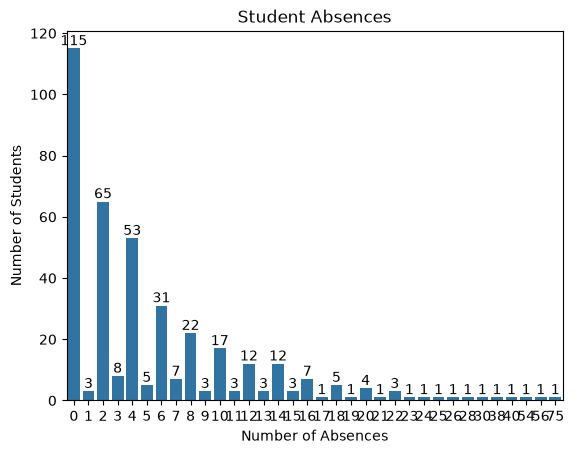

In [10]:
xy = sns.countplot(x = 'absences' , data = df)
for bars in xy.containers:
    xy.bar_label(bars)

plt.title('Student Absences')
plt.xlabel('Number of Absences')
plt.ylabel('Number of Students')

The distribution of absences is right skewed so most students have fewer absences but a small group of students have a lot higher absenses. We can also see this because the mean (5.71) is higher than the median (4).

([<matplotlib.axis.XTick at 0x1c457176350>,
 [Text(0, 0, '<2 hours'),
  Text(1, 0, '2-5 hours'),
  Text(2, 0, '5-10 hours'),
  Text(3, 0, '>10 hours')])

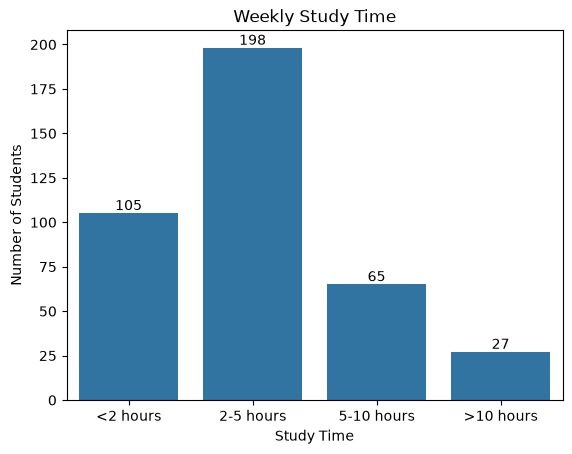

In [11]:
xy = sns.countplot(x = 'studytime' , data = df)
for bars in xy.containers:
    xy.bar_label(bars)

plt.title('Weekly Study Time')
plt.xlabel('Study Time')
plt.ylabel('Number of Students')
plt.xticks([0,1,2,3] , ['<2 hours' , '2-5 hours' , '5-10 hours' , '>10 hours'])
    

Most students report studying between 2-5 hours per week or less than 2 hours per week, with very few students studying more than 5 hours per week.

Text(0, 0.5, 'Number of Students')

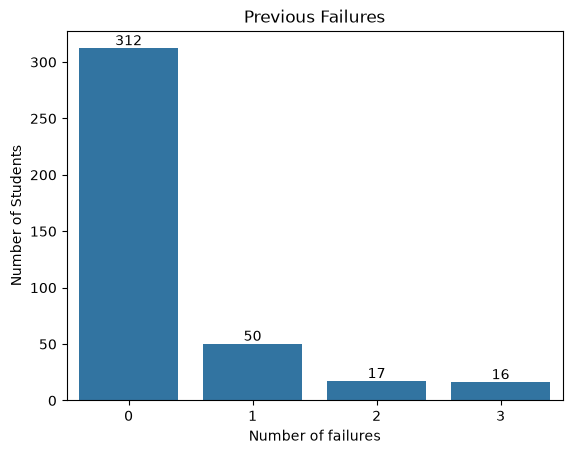

In [12]:
xy = sns.countplot(x = 'failures' , data = df)
for bars in xy.containers:
    xy.bar_label(bars)

plt.title('Previous Failures')
plt.xlabel('Number of failures')
plt.ylabel('Number of Students')
    

Most students have no previous failures, while a smaller number of students have experienced one or more failures.

Text(0, 0.5, 'Number of Students')

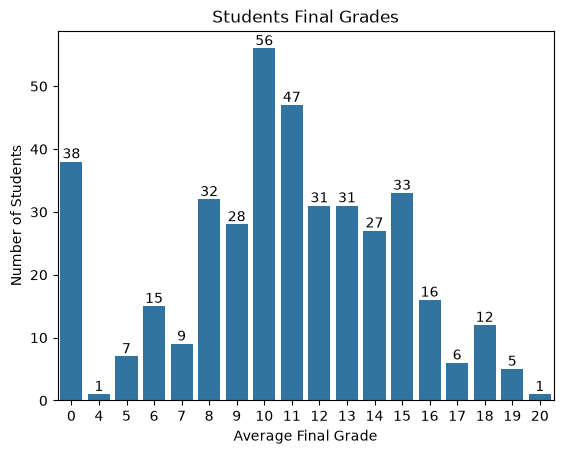

In [13]:
xy = sns.countplot(x = 'G3' , data = df)
for bars in xy.containers:
    xy.bar_label(bars)
    
plt.title('Students Final Grades')
plt.xlabel('Average Final Grade')
plt.ylabel('Number of Students')

Most students have final grades centered around 10-11, while fewer students have very low grades (including 0) or higher grades around 15 and above.

Text(0, 0.5, 'Average Final Grade')

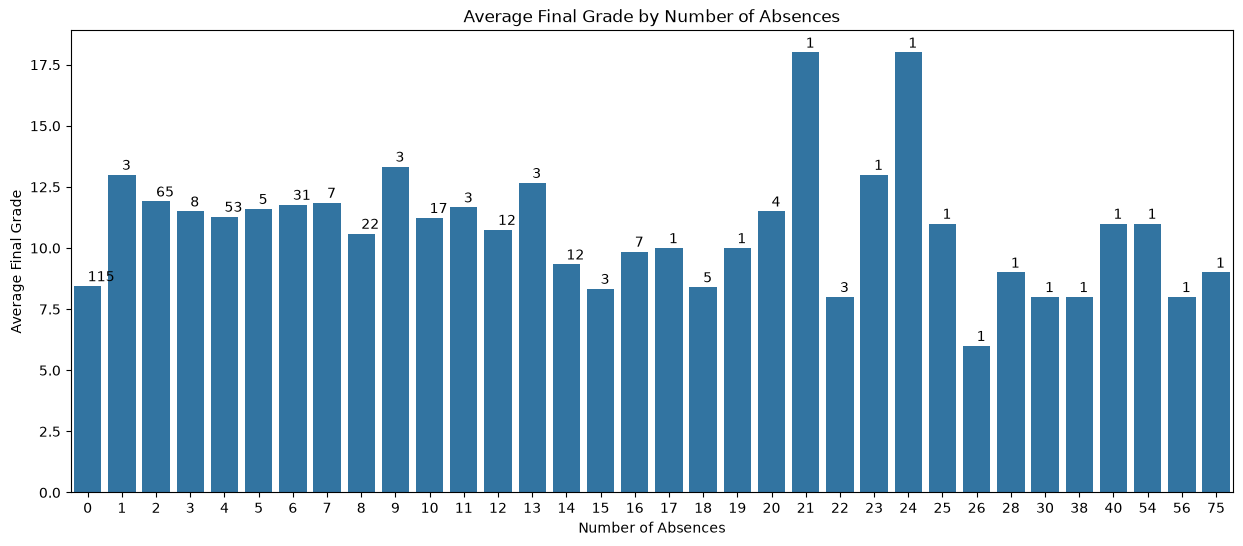

In [14]:
abs_grade = df.groupby('absences' , as_index=False).agg(
    avg_grade=('G3' , 'mean'), students=('G3' , 'count')
)
plt.figure(figsize=(15,6))

xy = sns.barplot(x='absences' , y='avg_grade' , data=abs_grade)

for i in range(len(abs_grade)):
    xy.text(i, abs_grade.avg_grade[i] + 0.2, abs_grade.students[i])

plt.title('Average Final Grade by Number of Absences')
plt.xlabel('Number of Absences')
plt.ylabel('Average Final Grade')


Most students had absences on the lower end (2-8) and average final grades between 10 and 12.5. Although some students with high numbers of absence (21-24) acieved high final grades, these groups had fewer students.

Text(0, 0.5, 'Average Final Grade')

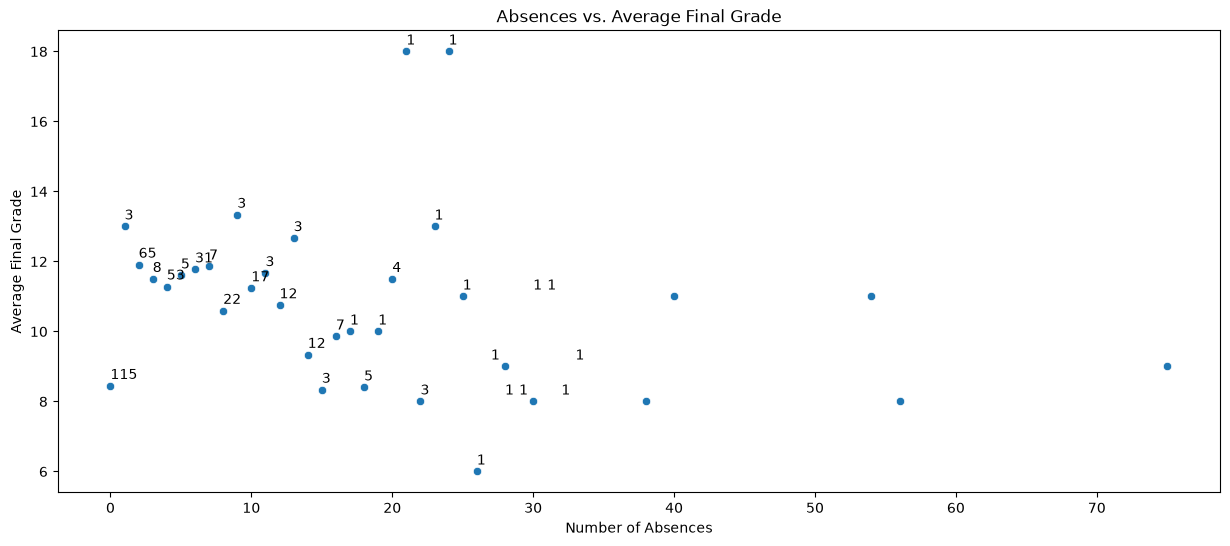

In [15]:
abs_grade = df.groupby('absences' , as_index=False).agg(
    avg_grade=('G3' , 'mean'), students=('G3' , 'count')
)
plt.figure(figsize=(15,6))

xy = sns.scatterplot(x='absences' , y='avg_grade' , data=abs_grade)

for i in range(len(abs_grade)):
    xy.text(i, abs_grade.avg_grade[i] + 0.2, abs_grade.students[i])

plt.title('Absences vs. Average Final Grade')
plt.xlabel('Number of Absences')
plt.ylabel('Average Final Grade')



The scatter plot does not show a clear linear relationship between absences and average final grade. Most students had fewer absences and average final grades between 10 and 14. While some students with higher numbers of absences also had relatively high average grades, these groups had fewer students.

([<matplotlib.axis.XTick at 0x1c459b16c10>,
 [Text(0, 0, '<2 hours'),
  Text(1, 0, '2-5 hours'),
  Text(2, 0, '5-10 hours'),
  Text(3, 0, '>10 hours')])

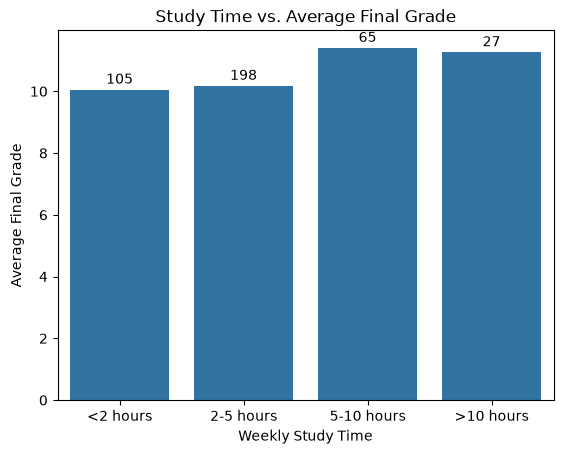

In [16]:
study_grade = df.groupby('studytime' , as_index=False).agg(
    avg_grade=('G3' , 'mean'), students=('G3' , 'count')
)
xy = sns.barplot(x='studytime' , y='avg_grade' , data=study_grade)

for i in range(len(study_grade)):
    xy.text(i, study_grade.avg_grade[i] + 0.2, study_grade.students[i], ha='center')

plt.title('Study Time vs. Average Final Grade')
plt.xlabel('Weekly Study Time')
plt.ylabel('Average Final Grade')
plt.xticks([0, 1, 2, 3], ['<2 hours', '2-5 hours', '5-10 hours', '>10 hours'])

Most students studied between 0-2 or 2-5 hours per week and  had average final grades around 10. Students who studied more than 5 hours per week had somewhat higher average final grades, although these groups had fewer students.

Text(0, 0.5, 'Average Final Grade')

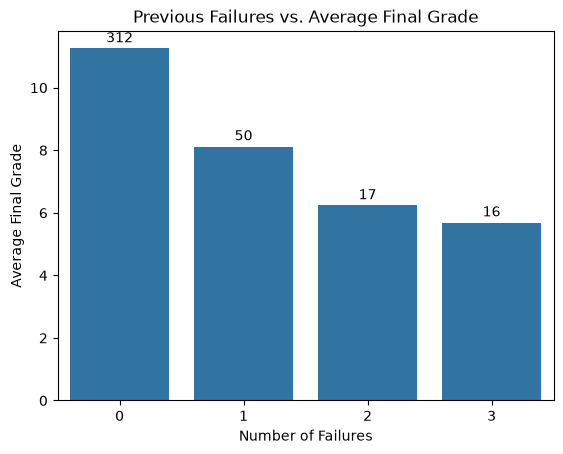

In [17]:
fail_grade = df.groupby('failures' , as_index=False).agg(
    avg_grade=('G3' , 'mean'), students=('G3' , 'count')
)
xy = sns.barplot(x='failures' , y='avg_grade' , data=fail_grade)

for i in range(len(fail_grade)):
    xy.text(i, fail_grade.avg_grade[i] + 0.2, fail_grade.students[i], ha='center')

plt.title('Previous Failures vs. Average Final Grade')
plt.xlabel('Number of Failures')
plt.ylabel('Average Final Grade')


Most students had no previous failures and had an average final grade above 10. Students with one or more previous failures had lower average final grades.

Overall, previous failures showed the clearest relationship with average final grades, compared to the other variables explored. Students with no previous failures had higher average final grades, while students with previous failures had lower averages. Study time showed some association with higher grades, especially with students who studied more than 5 hours per week, but these groups had fewer students. The relationship between absences and final grades was less consistent. 

Limitations: This analysis shows relationships between different student characteristics and final grades but it does not mean that one factor directly causes a change in grades. Some groups also had fewer students, which could make their average gradess less reliable. Finally, this analysis was limited to the variables inclded in the dataset.